# HW Y · 01 — Round 1: six changes, one at a time

**Baseline (end of Homework X):** ConvNeXt-S (ImageNet-22k), 448 px. It is distilled from the out-of-fold 5-backbone
ensemble and scored with TTA-20 and logit adjustment: **CV 0.888, test 0.864**. Everything up to this model is Homework X
work. This notebook covers only the new changes.

**Plan, written before any run (`research/plan.md`).** Each change is one flag of `scripts/train_classifier.py`. All 5
folds are trained with the same soft labels and seed.
- **Adopt** a change if its paired CV gain over the baseline is > 0 with at least 3 of 5 folds better.
- **The test set is reported, never used to choose.**
- **EMA** is judged against the raw weights of the same run.
- **Metadata** must also stay within 0.005 of the baseline when all its metadata is removed.

| Flag | Change |
|---|---|
| `--drop-path 0.2` | stochastic depth |
| `--layer-decay 0.8 --lr 4e-4` | layer-wise LR decay, 14 groups as in the ConvNeXt paper |
| `--img-width 600` | full-frame 448 × 600 input (same pixel scale, 34% more field of view) |
| `--lesion-boxes ...` | lesion-centred square crops from our lesion segmenter |
| `--metadata` | age / sex / body-site fusion with modality dropout |
| `--ema 0.999` | EMA copy of the weights, tracked in every run |

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

HWY_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWY_DIR))
from isic import analysis as A
from isic.data import CLASSES, LesionCrop, load_split

pd.set_option("display.width", 200)
RUN_TRAINING = False   # True on a GPU node: re-create one fold of the drop-path variant (~33 min) before the analysis

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWY_DIR)

BASE = "hwx/convnext_s_kd_res448_tta20_la"
FACTORS = {"drop path 0.2": "cnx_kd_r1_dp02", "layer-wise LR decay": "cnx_kd_r1_lld", "full frame 448x600": "cnx_kd_r1_rect",
           "lesion-centred crop": "cnx_kd_r1_lesion", "metadata fusion": "cnx_kd_r1_meta"}
la = lambda r: f"{r}_tta20_la"

In [2]:
if RUN_TRAINING:
    run("python scripts/train_classifier.py --run-name cnx_kd_r1_dp02 --model convnext_small.fb_in22k_ft_in1k --lr 2e-4 "
        "--img-size 448 --soft-labels results/hwx/soft_labels/bb5_calib_oof.csv --kd-alpha 0.5 --ema 0.999 --drop-path 0.2 --fold 0")
    run("python scripts/evaluate_tta.py cnx_kd_r1_dp02 --crops 5 --folds 0")
    run("python scripts/posthoc_logit_adjustment.py cnx_kd_r1_dp02_tta20")

## 0. Feasibility checks before any GPU run (`research/feasibility_checks.py`)
1. A logistic-regression stacker on the baseline's out-of-fold predictions, plus metadata.
2. How much a lesion-centred crop would zoom in.

The per-source table looked at test results. It was used for one design decision only: train the metadata model for
images with no metadata. Which test images lack metadata is known at prediction time.

In [3]:
fz = json.loads((A.RESULTS / "comparisons" / "feasibility.json").read_text())
display(pd.DataFrame(fz["metadata_stacker"]).set_index("stacker").round(4))
display(pd.DataFrame(fz["metadata_by_source"]).pivot(index="test subset", columns="training", values=["image only", "image + metadata"]).round(4))
pd.Series(fz["lesion_boxes"]).round(3)

,cv nested,test (per-fold mean)
stacker,,
image probs only,0.8815,0.8634
metadata only,0.3489,0.2552
image probs + metadata,0.8823,0.8345


image only                               image + metadata                             
training               metadata as given with metadata-removed copies metadata as given with metadata-removed copies
test subset                                                                                                         
HAM sources                       0.8664                       0.8664            0.8842                       0.8792
all test                          0.8634                       0.8634            0.8345                       0.8670
external (no metadata)            0.8894                       0.8894            0.7832                       0.8837

area_median       0.238
touches_border    0.202
zoom_gt_1.25      0.255
zoom_gt_1.5       0.160
zoom_median       0.891
dtype: float64

## 1. Results: each change against the baseline (TTA-20 + logit adjustment, 5 folds)

In [4]:
runs = [BASE] + [la(r) for r in FACTORS.values()]
names = ["baseline (HW X)"] + list(FACTORS)
display(A.summary(runs, names=names)[["bal_acc", "auc", "mel_sens", "ensemble_bal_acc"]])
display(A.summary(runs, split="cv_val", names=names, ensemble=False)[["bal_acc", "auc"]].rename(columns=lambda c: "cv_" + c))
A.paired_table([la(r) for r in FACTORS.values()], BASE, names=list(FACTORS))

,bal_acc,auc,mel_sens,ensemble_bal_acc
baseline (HW X),0.864 ± 0.010,0.983 ± 0.001,0.795 ± 0.018,0.867
drop path 0.2,0.869 ± 0.010,0.984 ± 0.001,0.821 ± 0.012,0.878
layer-wise LR decay,0.864 ± 0.006,0.982 ± 0.000,0.816 ± 0.018,0.867
full frame 448x600,0.864 ± 0.009,0.983 ± 0.001,0.819 ± 0.016,0.862
lesion-centred crop,0.862 ± 0.004,0.981 ± 0.001,0.802 ± 0.021,0.868
metadata fusion,0.863 ± 0.007,0.983 ± 0.001,0.813 ± 0.013,0.873


,cv_bal_acc,cv_auc
baseline (HW X),0.888 ± 0.020,0.990 ± 0.001
drop path 0.2,0.895 ± 0.014,0.990 ± 0.002
layer-wise LR decay,0.886 ± 0.012,0.989 ± 0.002
full frame 448x600,0.896 ± 0.012,0.990 ± 0.001
lesion-centred crop,0.887 ± 0.012,0.988 ± 0.002
metadata fusion,0.887 ± 0.021,0.989 ± 0.001


,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
drop path 0.2,+0.007 ± 0.011 (4/5),+0.032 ± 0.043 (4/5),+0.001 ± 0.001 (3/5),+0.005 ± 0.017 (3/5),+0.026 ± 0.025 (4/5),+0.001 ± 0.001 (4/5)
layer-wise LR decay,-0.002 ± 0.016 (2/5),+0.022 ± 0.025 (3/5),-0.001 ± 0.002 (2/5),+0.000 ± 0.008 (2/5),+0.021 ± 0.017 (4/5),-0.000 ± 0.001 (2/5)
full frame 448x600,+0.008 ± 0.017 (3/5),+0.021 ± 0.028 (4/5),+0.001 ± 0.001 (4/5),-0.000 ± 0.016 (3/5),+0.023 ± 0.029 (4/5),+0.001 ± 0.001 (4/5)
lesion-centred crop,-0.001 ± 0.014 (2/5),+0.005 ± 0.020 (3/5),-0.001 ± 0.001 (1/5),-0.002 ± 0.007 (3/5),+0.007 ± 0.031 (2/5),-0.001 ± 0.001 (0/5)
metadata fusion,-0.001 ± 0.011 (2/5),+0.005 ± 0.023 (2/5),-0.000 ± 0.000 (1/5),-0.001 ± 0.014 (2/5),+0.018 ± 0.030 (3/5),-0.000 ± 0.001 (2/5)


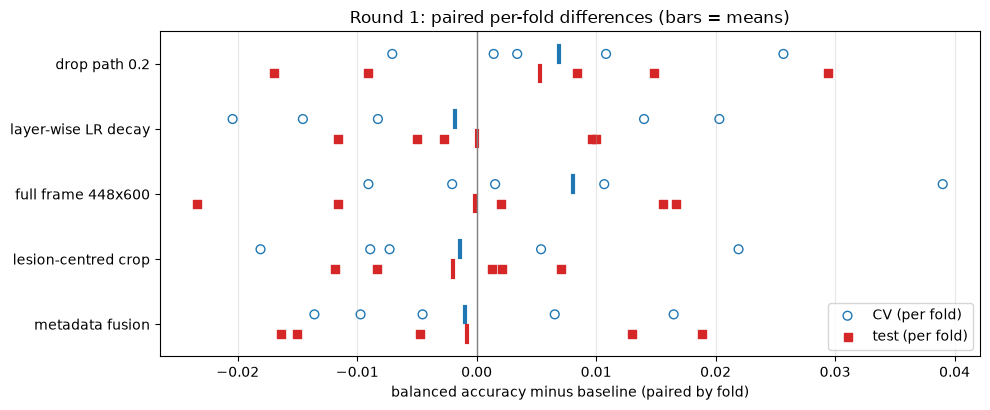

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (name, r) in enumerate(FACTORS.items()):
    for j, (split, mk, col) in enumerate((("cv_val", "o", "C0"), ("official_test", "s", "C3"))):
        d = A.per_fold(la(r), split).bal_acc.to_numpy() - A.per_fold(BASE, split).bal_acc.to_numpy()
        y = i + (j - 0.5) * 0.3
        ax.scatter(d, [y] * 5, marker=mk, facecolors="none" if j == 0 else col, edgecolors=col, s=40,
                   label=("CV" if j == 0 else "test") + " (per fold)" if i == 0 else None)
        ax.plot([d.mean()] * 2, [y - 0.12, y + 0.12], color=col, lw=3)
ax.axvline(0, color="grey", lw=1); ax.set_yticks(range(len(FACTORS)), list(FACTORS)); ax.invert_yaxis()
ax.set_xlabel("balanced accuracy minus baseline (paired by fold)"); ax.grid(axis="x", alpha=.3); ax.legend(loc="lower right")
ax.set_title("Round 1: paired per-fold differences (bars = means)"); plt.tight_layout()

In [6]:
pd.DataFrame({n: A.per_class_recall(r) for n, r in zip(names, runs)}).round(3)

,baseline (HW X),drop path 0.2,layer-wise LR decay,full frame 448x600,lesion-centred crop,metadata fusion
MEL,0.795,0.821,0.816,0.819,0.802,0.813
NV,0.873,0.866,0.847,0.873,0.844,0.864
BCC,0.886,0.875,0.860,0.877,0.869,0.867
AKIEC,0.921,0.874,0.893,0.888,0.898,0.893
BKL,0.823,0.828,0.823,0.819,0.806,0.829
DF,0.823,0.877,0.882,0.832,0.855,0.850
VASC,0.926,0.943,0.926,0.937,0.960,0.926


In [7]:
pd.DataFrame({n: A.per_source(r) for n, r in zip(names, runs)}).T.round(4)   # test only: HAM10000 clinics vs the new 'external' source

,HAM sources,external
baseline (HW X),0.8637,0.8919
drop path 0.2,0.8653,0.9007
layer-wise LR decay,0.8636,0.8883
full frame 448x600,0.8592,0.8959
lesion-centred crop,0.8589,0.8869
metadata fusion,0.8552,0.8937


## 2. EMA: better on test, worse on CV — checkpoint selection explains it
Every run kept an EMA copy of the weights (decay 0.999), selected and scored like the raw weights.

In [8]:
rows = []
for name, r in {"re-run": "cnx_kd_r1_base", **FACTORS}.items():
    cv_mu, _, cv_b, _ = A.paired(la(f"{r}_ema"), la(r), "cv_val"); te_mu, _, te_b, _ = A.paired(la(f"{r}_ema"), la(r))
    h = A.history(r); g = h.groupby("fold"); last = h[h.epoch == h.epoch.max()]
    rows.append({"run": name, "CV EMA-raw (best epoch, TTA+LA)": cv_mu, "folds": f"{cv_b}/5", "test EMA-raw": te_mu, "test folds": f"{te_b}/5",
                 "raw: best - last epoch (CV)": g.val_balanced_acc.max().mean() - last.val_balanced_acc.mean(),
                 "EMA: best - last epoch (CV)": g.val_balanced_acc_ema.max().mean() - last.val_balanced_acc_ema.mean(),
                 "last epoch EMA-raw (CV)": last.val_balanced_acc_ema.mean() - last.val_balanced_acc.mean()})
pd.DataFrame(rows).set_index("run").round(4)

,"CV EMA-raw (best epoch, TTA+LA)",folds,test EMA-raw,test folds,raw: best - last epoch (CV),EMA: best - last epoch (CV),last epoch EMA-raw (CV)
run,,,,,,,
re-run,-0.0043,1/5,0.0015,2/5,0.0159,0.0101,0.0006
drop path 0.2,-0.0044,1/5,0.0043,4/5,0.0105,0.0084,-0.0013
layer-wise LR decay,-0.0027,0/5,0.0041,4/5,0.0141,0.0100,0.0013
full frame 448x600,-0.0022,2/5,0.0032,2/5,0.0135,0.0085,-0.0014
lesion-centred crop,-0.0018,2/5,0.0072,5/5,0.0130,0.0084,-0.0000
metadata fusion,0.0029,2/5,0.0064,5/5,0.0108,0.0078,-0.0004


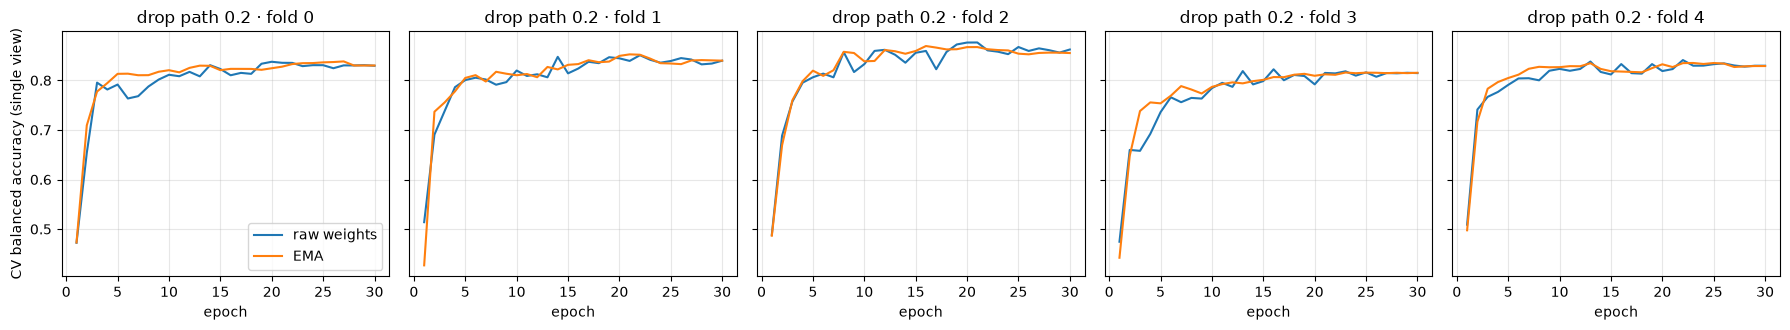

In [9]:
h = A.history("cnx_kd_r1_dp02")
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
for k, ax in enumerate(axes):
    f = h[h.fold == k]
    ax.plot(f.epoch, f.val_balanced_acc, label="raw weights"); ax.plot(f.epoch, f.val_balanced_acc_ema, label="EMA")
    ax.set_title(f"drop path 0.2 · fold {k}"); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("CV balanced accuracy (single view)"); axes[0].legend(); plt.tight_layout()

The raw curve jumps about twice as much from epoch to epoch as the EMA curve. Taking the best of 30 epochs on the same
CV fold that is then scored therefore lifts the raw weights more. At the last epoch, where nothing is selected, raw and
EMA are equal on CV. EMA stays out, as the pre-registered rule says. Round 2 re-tests it with a cross-fitted CV score.

## 3. Metadata fusion: does the model use its metadata?

In [10]:
r = "cnx_kd_r1_meta_tta20_la"
display(pd.DataFrame({s: A.per_fold(r, s).bal_acc for s in ["cv_val", "cv_val_nometa", "official_test", "official_test_nometa"]}).agg(["mean", "std"]).round(4))
tv, flips = [], []
for k in range(5):
    a = pd.read_csv(A.RESULTS / r / f"fold{k}" / "pred_cv_val.csv")[CLASSES].to_numpy()
    b = pd.read_csv(A.RESULTS / r / f"fold{k}" / "pred_cv_val_nometa.csv")[CLASSES].to_numpy()
    tv.append(np.abs(a - b).sum(1).mean() / 2); flips.append((a.argmax(1) != b.argmax(1)).mean())
print(f"removing all metadata: mean total-variation change {np.mean(tv):.4f}, prediction changes for {np.mean(flips):.2%} of CV images")

,cv_val,cv_val_nometa,official_test,official_test_nometa
mean,0.887,0.8868,0.8630,0.8627
std,0.024,0.0241,0.0081,0.0077


removing all metadata: mean total-variation change 0.0021, prediction changes for 0.21% of CV images


## 4. Lesion segmenter and lesion-centred crops

{'oof_jaccard_mean': 0.9115712928911934, 'oof_jaccard_median': 0.9488348352576739, 'oof_jaccard_below_0.65': 0.02855716425361957, 'n_boxes': 11720, 'empty_masks': 0}
per-fold best val Jaccard: [0.9101, 0.9106, 0.9146, 0.9123, 0.9104]


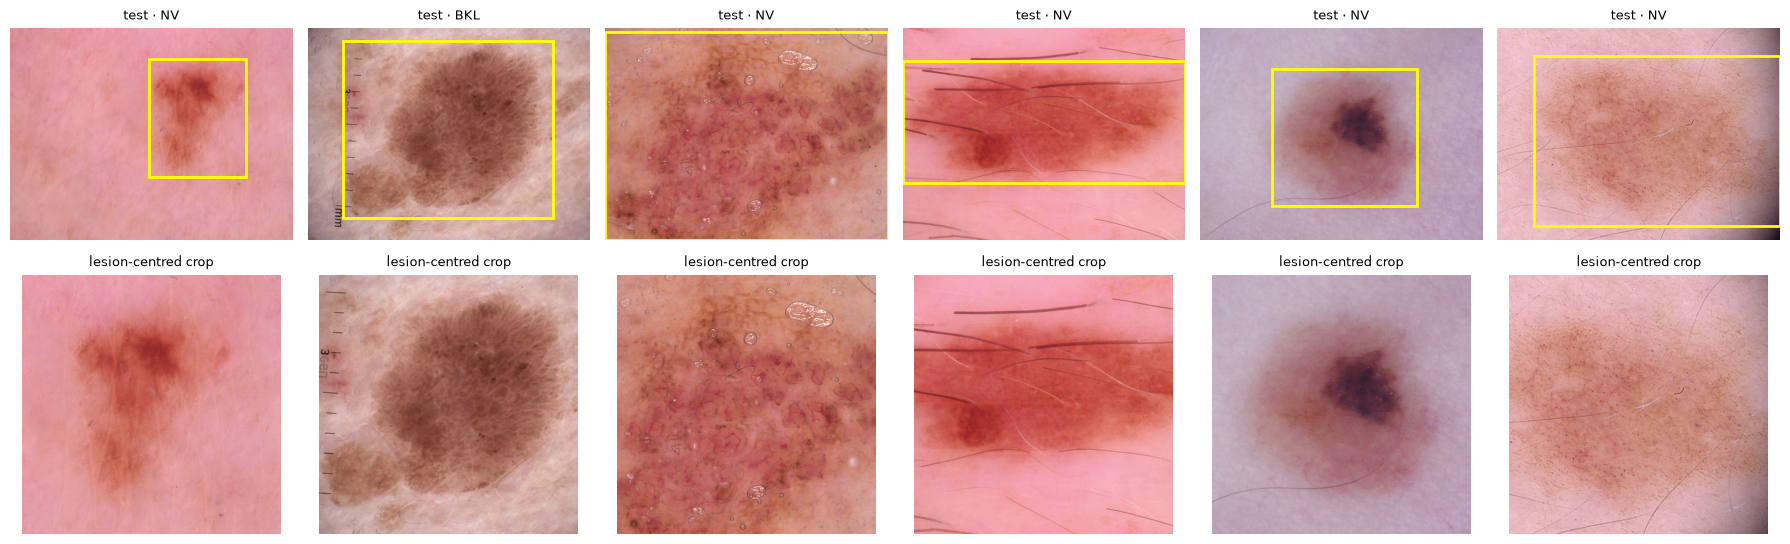

In [11]:
print(json.loads((A.RESULTS / "lesion_seg" / "boxes_summary.json").read_text()))
print("per-fold best val Jaccard:", [round(json.loads((A.RESULTS / "lesion_seg" / f"fold{k}" / "metrics.json").read_text())["best_val_jaccard"], 4) for k in range(5)])
boxes = pd.read_csv(A.RESULTS / "lesion_seg" / "boxes.csv").set_index("image")
te = load_split("test").sample(6, random_state=1)
crop = LesionCrop(train=False)
fig, axes = plt.subplots(2, 6, figsize=(18, 5.6))
for j, row in enumerate(te.itertuples()):
    im = Image.open(row.path).convert("RGB"); b = boxes.loc[row.image, ["x0", "y0", "x1", "y1"]].to_numpy(float)
    axes[0, j].imshow(im); axes[0, j].add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec="yellow", lw=2))
    axes[0, j].set_title(f"test · {row.dx}", fontsize=9); axes[1, j].imshow(crop(im, b)); axes[1, j].set_title("lesion-centred crop", fontsize=9)
    for a in axes[:, j]: a.axis("off")
plt.tight_layout()

## Takeaways
* **Adopted:** drop path 0.2 (CV +0.007, 4/5 folds; test 0.864 → **0.869**) and full-frame 448 × 600 input (CV +0.008,
  3/5; test flat). Round 2 combines them.
* **Not adopted:** layer-wise LR decay (−0.002), lesion-centred crops (−0.001, even with a segmenter at 0.91 Jaccard),
  metadata fusion (−0.001; the model ignores its metadata), and EMA (worse on CV in 5 of 6 runs).
* **Lesson about the protocol:** EMA was better on test in all 6 runs, but choosing the best epoch on the CV fold rewards
  the noisier raw weights. A CV estimate needs to account for its own model selection. Round 2 uses a cross-fitted score
  for this.
* An identical re-run reproduced Homework X bit for bit, so noise has to be measured with a different seed (Round 2).